<a href="https://colab.research.google.com/github/giabq/plnEp2/blob/main/CatBoost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clonagem do repositório (comentar se estiver rodando local)

In [ ]:
!git clone https://github.com/giabq/plnEp2

%cd plnEp2

Cloning into 'plnEp2'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 39 (delta 12), reused 15 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 12.74 MiB | 17.26 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/plnEp2


# Instalar e importar bibliotecas

In [ ]:
!pip install -q catboost openpyxl

In [ ]:
import os
import re
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier

from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


# Checando a estrutura do repo

In [ ]:
print("Arquivos disponíveis:")

for root, dirs, files in os.walk("data"):
    for file in files:
        print(os.path.join(root, file))

Arquivos disponíveis:
data/test1_limpo.csv
data/train_limpo.csv
data/test2_limpo.csv
data/test2.xlsx
data/test1-rotulado-para-teste-estatistico.xlsx
data/train.csv
data/test1.xlsx
data/test1_rotulado_ep1.xlsx


# Carregar os conjuntos de dados

Vamos utilizar:
- train_limpo.csv: textos de treinamento já pré-processados.
- test1_rotulado_para_teste-estatistico.xlsx: conjunto de teste 1 com os rótulos disponibilizados para a comparação estatística.

In [ ]:
train = pd.read_csv("data/train_limpo.csv")

test1 = pd.read_excel(
    "data/test1-rotulado-para-teste-estatistico.xlsx"
)

print("Treinamento:", train.shape)
print("Teste 1:", test1.shape)

Treinamento: (20092, 2)
Teste 1: (900, 2)


# Checando colunas e registros dos dados carregados

In [ ]:
print("COLUNAS DO TREINAMENTO:")
print(train.columns.tolist())

print("\nPRIMEIROS REGISTROS DO TREINAMENTO:")
display(train.head())

print("\nCOLUNAS DO TESTE 1:")
print(test1.columns.tolist())

print("\nPRIMEIROS REGISTROS DO TESTE 1:")
display(test1.head())

COLUNAS DO TREINAMENTO:
['resp_text', 'clarity']

PRIMEIROS REGISTROS DO TREINAMENTO:


,resp_text,clarity
0,prezado a senhor a esclarecemos que o serviço ...,c5
1,prezada cidadã as informações sobre óbitos no ...,c1
2,prezado senhor julio a ouvidoria geral da petr...,c1
3,prezado a senhor a esclarecemos que o serviço ...,c234
4,senhor o serviço de informações ao cidadão do ...,c234



COLUNAS DO TESTE 1:
['resp_text', 'clarity']

PRIMEIROS REGISTROS DO TESTE 1:


,resp_text,clarity
0,"Prezada Hellen, Dentre as pesquisas domici...",c5
1,"Senhor Francisco, O Serviço de Informações a...",c1
2,"Prezada Srª. Raylane, Em resposta a sua solic...",c5
3,"Prezada Senhora, De acordo com o art.13 do D...",c1
4,"Prezado(a) Senhor(a), Em atendimento ao ped...",c234


#Checando os dados e a distribuição das classes

In [ ]:
print("Dimensões:")
print(f"Treinamento: {train.shape}")
print(f"Teste 1: {test1.shape}")

print("\nValores ausentes:")
print(train.isnull().sum())

print("\nDistribuição das classes no treinamento:")
display(train["clarity"].value_counts())

print("\nDistribuição percentual:")
display(train["clarity"].value_counts(normalize=True) * 100)

print("\nDistribuição das classes no Teste 1:")
display(test1["clarity"].value_counts())

Dimensões:
Treinamento: (20092, 2)
Teste 1: (900, 2)

Valores ausentes:
resp_text    0
clarity      0
dtype: int64

Distribuição das classes no treinamento:


,count
clarity,
c5,6892
c234,6853
c1,6347



Distribuição percentual:


,proportion
clarity,
c5,34.302210
c234,34.108103
c1,31.589687



Distribuição das classes no Teste 1:


,count
clarity,
c5,300
c1,300
c234,300


#Preparando as variávies de entrada

In [ ]:
# Textos
X_train_text = train["resp_text"].fillna("").astype(str)
X_test_text = test1["resp_text"].fillna("").astype(str)

# Rótulos
y_train = train["clarity"].str.strip().str.lower()
y_test = test1["clarity"].str.strip().str.lower()

# Verificar as classes
print("Classes encontradas:", sorted(y_train.unique()))

assert set(y_train.unique()) == {"c1", "c234", "c5"}
assert set(y_test.unique()).issubset({"c1", "c234", "c5"})

print("\nVariáveis preparadas!")

Classes encontradas: ['c1', 'c234', 'c5']

Variáveis preparadas!


#Implementando a extração de características

In [ ]:
def extract_features(text):

    words = text.split()

    num_words = len(words)
    num_chars = len(text)

    if num_words > 0:

        word_lengths = [len(word) for word in words]

        avg_word_length = np.mean(word_lengths)
        max_word_length = np.max(word_lengths)

        unique_words = len(set(words))

        lexical_diversity = unique_words / num_words

        long_words_ratio = (
            sum(length >= 7 for length in word_lengths) / num_words
        )

    else:

        avg_word_length = 0
        max_word_length = 0
        lexical_diversity = 0
        long_words_ratio = 0

    return {
        "num_chars": num_chars,
        "num_words": num_words,
        "avg_word_length": avg_word_length,
        "max_word_length": max_word_length,
        "lexical_diversity": lexical_diversity,
        "long_words_ratio": long_words_ratio
    }

#Construção das matrizes de entrada

In [ ]:
def build_features(texts):

    features = pd.DataFrame(
        [extract_features(text) for text in texts]
    )

    features.index = texts.index

    result = pd.DataFrame({
        "resp_text": texts
    })

    result = pd.concat(
        [result, features],
        axis=1
    )

    return result


X_train = build_features(X_train_text)
X_test = build_features(X_test_text)

print("Dimensões do treinamento:", X_train.shape)
print("Dimensões do teste:", X_test.shape)

display(X_train.head())

Dimensões do treinamento: (20092, 7)
Dimensões do teste: (900, 7)


,resp_text,num_chars,num_words,avg_word_length,max_word_length,lexical_diversity,long_words_ratio
0,prezado a senhor a esclarecemos que o serviço ...,2116,327,5.474006,15,0.614679,0.406728
1,prezada cidadã as informações sobre óbitos no ...,928,154,5.032468,16,0.571429,0.279221
2,prezado senhor julio a ouvidoria geral da petr...,1226,199,5.165829,16,0.703518,0.386935
3,prezado a senhor a esclarecemos que o serviço ...,3309,500,5.620000,17,0.580000,0.416000
4,senhor o serviço de informações ao cidadão do ...,604,91,5.648352,15,0.703297,0.417582


#Configurando o Grid-search
Estamos testando essas configurações p busca:

iterations	300, 500

depth	4, 6

learning_rate	0.03, 0.1

l2_leaf_reg	3, 5

In [20]:
catboost_model = CatBoostClassifier(
    loss_function="MultiClass",
    eval_metric="Accuracy",

    random_seed=RANDOM_STATE,

    verbose=False,
    allow_writing_files=False,
    thread_count=2
)


# Hiperparâmetros investigados
param_grid = {
    "iterations": [300, 500],
    "depth": [4, 6],
    "learning_rate": [0.03, 0.1],
    "l2_leaf_reg": [3, 5]
}


# Validação cruzada estratificada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


print("Combinações de hiperparâmetros:",
      len(list(ParameterGrid(param_grid))))

print("Número de folds:", cv.get_n_splits())

Combinações de hiperparâmetros: 16
Número de folds: 5


#Executando o Grid Search com Validação Cruzada

In [21]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=catboost_model,

    param_grid=param_grid,

    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },

    refit="accuracy",

    cv=cv,

    n_jobs=1,

    verbose=2,

    return_train_score=True,

    error_score="raise"
)


# Executar a busca
grid_search.fit(
    X_train,
    y_train,
    text_features=["resp_text"]
)


print("\nGrid Search finalizado!")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time= 1.0min
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time= 1.3min
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time= 1.1min
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time=  58.8s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time=  58.9s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.1; total time=  59.0s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.1; total time=  58.8s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.1; total time=  58.6s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.1; total time=  57.6s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.1; total time=  58.0s
[CV] END depth=4, iterations=300, l2_leaf_reg=5, learning_rate=0

#Analisando os melhores hiperparametros (resultados do grid search)

In [24]:
# Gerar previsões para o Teste 1 usando o melhor modelo encontrado
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test).ravel()

# Garantir que os rótulos reais estejam no mesmo formato
y_test = test1["clarity"].astype(str).str.lower()

print("Previsões geradas:", len(y_pred))
print("Rótulos reais:", len(y_test))

Previsões geradas: 900
Rótulos reais: 900


#Avaliação no conjunto de Teste 1
##Calcular métricas de avaliação

In [25]:

accuracy = accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("RESULTADOS NO TESTE 1")
print("-" * 40)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

print("\nRELATÓRIO POR CLASSE:")

print(
    classification_report(
        y_test,
        y_pred,
        labels=["c1", "c234", "c5"],
        zero_division=0
    )
)

RESULTADOS NO TESTE 1
----------------------------------------
Accuracy: 0.4567
Macro-F1: 0.4459

RELATÓRIO POR CLASSE:
              precision    recall  f1-score   support

          c1       0.43      0.67      0.52       300
        c234       0.43      0.31      0.36       300
          c5       0.55      0.39      0.46       300

    accuracy                           0.46       900
   macro avg       0.47      0.46      0.45       900
weighted avg       0.47      0.46      0.45       900



#Matriz de confusão

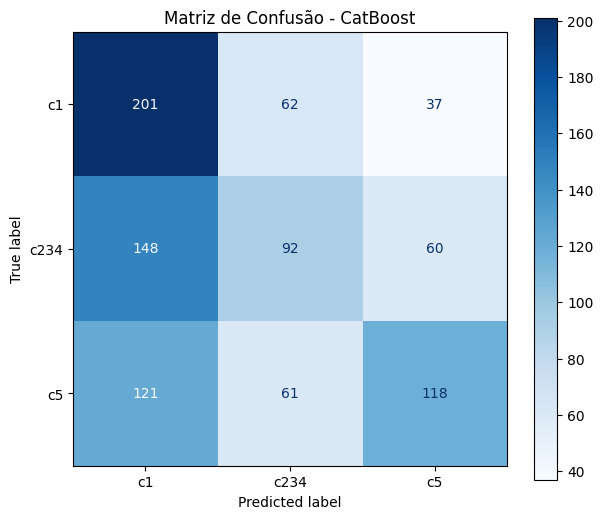

In [26]:
labels = ["c1", "c234", "c5"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Matriz de Confusão - CatBoost")
plt.show()

#Análise de características
##Importância de características

,feature,importance
0,resp_text,90.602158
6,long_words_ratio,2.236798
3,avg_word_length,2.224699
2,num_words,1.613431
5,lexical_diversity,1.547674
1,num_chars,1.300074
4,max_word_length,0.475166


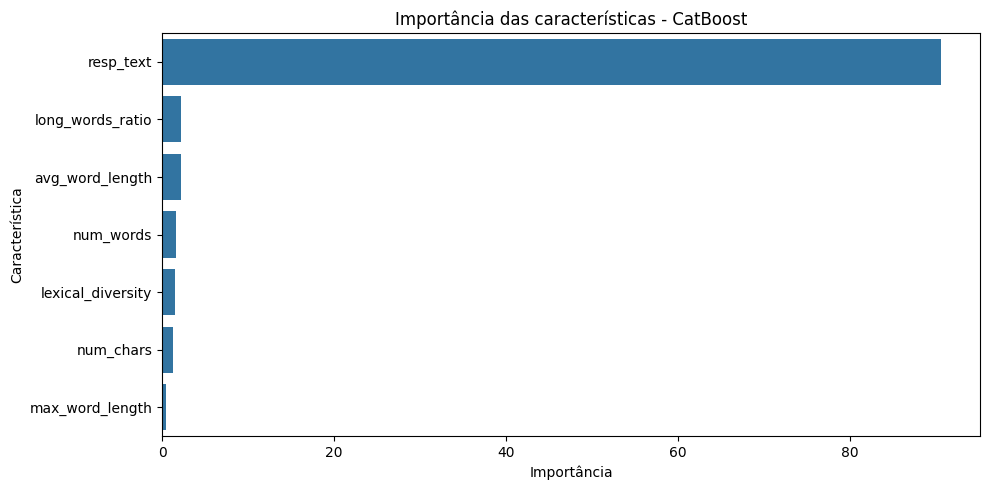

In [27]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

display(feature_importance)


# Visualização
plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title("Importância das características - CatBoost")
plt.xlabel("Importância")
plt.ylabel("Característica")

plt.tight_layout()
plt.show()